In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## **Load Datasets**

In [5]:
file_path = "/content/AssessmentDataScientist.xlsx"

In [6]:
# Load both sheets from the excel

application_df = pd.read_excel(
    file_path,
    sheet_name="Application Data",
    engine="openpyxl"
)

loanPerformance_df = pd.read_excel(
    file_path,
    sheet_name="Loan Performance",
    engine="openpyxl"
)



In [7]:
application_df.shape, loanPerformance_df.shape

((647, 31), (1285, 2))

In [8]:
application_df.head()

,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636


In [9]:
loanPerformance_df.head()

,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


In [10]:
application_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 647 entries, 0 to 646
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   customer_id                  647 non-null    object        
 1   amount_requested             647 non-null    int64         
 2   birth_date                   647 non-null    datetime64[ns]
 3   status                       647 non-null    object        
 4   residence_rent_or_own        647 non-null    bool          
 5   monthly_rent_amount          647 non-null    int64         
 6   bank_account_direct_deposit  647 non-null    bool          
 7   application_when             647 non-null    datetime64[ns]
 8   loan_duration                647 non-null    int64         
 9   payment_ach                  647 non-null    bool          
 10  num_payments                 647 non-null    int64         
 11  payment_amount               647 non-null    

In [11]:
loanPerformance_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1285 entries, 0 to 1284
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   idLoan   1285 non-null   object
 1   flgGood  1285 non-null   object
dtypes: object(2)
memory usage: 20.2+ KB


## **Basic Understanding about the data**

In [12]:
print("Application Data Columns:")
print(application_df.columns.tolist())

print("\nLoan Performance Columns:")
print(loanPerformance_df.columns.tolist())

Application Data Columns:
['customer_id', 'amount_requested', 'birth_date', 'status', 'residence_rent_or_own', 'monthly_rent_amount', 'bank_account_direct_deposit', 'application_when', 'loan_duration', 'payment_ach', 'num_payments', 'payment_amount', 'amount_approved', 'duration_approved', 'payment_amount_approved', 'address_zip', 'email', 'bank_routing_number', 'email_duration', 'residence_duration', 'bank_account_duration', 'payment_frequency', 'home_phone_type', 'other_phone_type', 'how_use_money', 'monthly_income_amount', 'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail', 'raw_FICO_bank_card', 'raw_FICO_money']

Loan Performance Columns:
['idLoan', 'flgGood']


### **Data Dictionary & Column Explanations**


---

#### **1. Application Data (`application_df`)**
These columns capture applicant demographics, financial situations, loan details requested vs. approved, and credit/telecom bureau scores at the time of application.

*   **`customer_id`**: A unique identifier for each customer. This is crucial for linking application-level data with performance outcomes (by matching against `idLoan` prefixes).
*   **`amount_requested`**: The loan principal amount requested by the applicant. Useful to understand credit demand and risk behavior.
*   **`birth_date`**: The applicant's date of birth. Used to calculate age, which is a key demographic factor (e.g., assessing credit stability based on life stage).
*   **`status`**: The state of the application (e.g., 'Approved'). It confirms whether the application progressed to a final loan state.
*   **`residence_rent_or_own`**: Boolean flag indicating whether the applicant rents (`True`) or owns (`False`) their home. Homeownership is highly correlated with financial stability and asset collateral.
*   **`monthly_rent_amount`**: The monthly cost of housing (rent/mortgage). Used to calculate debt-to-income ratios and remaining disposable income.
*   **`bank_account_direct_deposit`**: Boolean flag indicating if the applicant receives salary via direct deposit. Direct deposit typically signifies regular employment and reliable cash flow.
*   **`application_when`**: The precise timestamp when the application was submitted. Crucial for assessing temporal trends, macroeconomic factors, or seasonal behaviors.
*   **`loan_duration`**: The requested term of the loan (e.g., in months or bi-weekly cycles).
*   **`payment_ach`**: Boolean indicating if payments are made via Automated Clearing House (ACH) direct debit. ACH typically reduces default risk due to automated collection.
*   **`num_payments`**: The number of scheduled payments for the loan.
*   **`payment_amount`**: The scheduled amount of money to be paid back in each cycle.
*   **`amount_approved`**: The actual loan principal approved by the underwriting team. Discrepancies between this and `amount_requested` can reveal risk mitigation strategies.
*   **`duration_approved`**: The actual approved term duration of the loan.
*   **`payment_amount_approved`**: The approved installment payment amount.
*   **`address_zip`**: Postal ZIP code. Useful for geographic risk analysis (underwriting models often map location-specific demographic and default risks).
*   **`email`**: The email address of the applicant (often masked or checked for domain trust/validity as a fraud signal).
*   **`bank_routing_number`**: Identifies the applicant's financial institution. Certain banks/routing codes might historically correlate with higher fraud or delinquency rates.
*   **`email_duration`**: Indicates how long the email account has been active. Newer emails are often associated with higher fraud risk.
*   **`residence_duration`**: Length of time lived at the current address. Long-term residence indicates stability.
*   **`bank_account_duration`**: How long the applicant has held their active bank account. Older accounts represent mature financial history.
*   **`payment_frequency`**: How often repayments are scheduled (e.g., Bi-weekly, Semi-monthly, Monthly). Ideally aligns with the customer's pay cycle.
*   **`home_phone_type`**: The category of home phone (e.g., Mobile, Landline, VoIP). Landlines often represent higher stability, whereas VoIP might signal fraud.
*   **`other_phone_type`**: Type of secondary phone contact provided.
*   **`how_use_money`**: The self-reported reason for requesting the loan (e.g., medical, bills, auto-repair, etc.).
*   **`monthly_income_amount`**: The applicant's self-reported or verified gross monthly income. The fundamental metric for evaluating repayment capacity.
*   **`raw_l2c_score`**: L2C (Link2Credit) custom alternative credit score, frequently used for subprime/thin-file populations who lack traditional FICO scores.
*   **`raw_FICO_telecom`**: A specialized FICO credit risk score utilizing telecommunication payment histories.
*   **`raw_FICO_retail`**: A FICO score reflecting payment behaviors in retail credit programs.
*   **`raw_FICO_bank_card`**: Traditional FICO score tailored to predict risk on credit cards.
*   **`raw_FICO_money`**: A FICO score predictive of payment risk in personal loans and money services.

---

#### **2. Loan Performance (`loanPerformance_df`)**
This dataset tracks the actual repayment outcomes of the issued loans.

*   **`idLoan`**: Unique identifier for each issued loan (formatted with a suffix like `-01` or `-02`, matching the `customer_id` prefix). This acts as the key to join the outcome back to the original application details.
*   **`flgGood`**: The target label (`Good` vs `Bad`).
    *   `Good`: The borrower paid back the loan successfully according to terms.
    *   `Bad`: The borrower defaulted or became severely delinquent. This is the dependent variable we aim to predict in credit scoring.

In [13]:
application_df.describe()

,amount_requested,birth_date,monthly_rent_amount,application_when,loan_duration,num_payments,payment_amount,amount_approved,duration_approved,payment_amount_approved,address_zip,bank_routing_number,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
count,647.000000,647,647.000000,647,647.000000,647.000000,647.000000,647.000000,647.000000,627.000000,647.000000,6.470000e+02,647.000000,647.000000,647.000000,647.000000,647.000000,647.000000
mean,597.604328,1968-06-05 06:53:58.330757344,585.265842,2011-02-07 14:58:10.460587264,5.925811,10.264297,116.575178,525.347759,5.540958,113.293206,81524.528594,1.811344e+08,2617.151468,594.102009,568.927357,596.774343,665.174652,603.151468
min,250.000000,1931-03-11 00:00:00,0.000000,2010-10-16 14:06:05,2.000000,3.000000,35.210000,250.000000,2.000000,31.500000,57003.000000,1.240000e+04,300.000000,50.000000,222.000000,222.000000,222.000000,222.000000
25%,500.000000,1959-09-13 00:00:00,270.000000,2011-01-03 17:06:08,5.000000,6.000000,77.390000,500.000000,5.000000,77.390000,83704.000000,1.240001e+08,1502.000000,539.500000,537.500000,556.000000,646.500000,588.000000
50%,500.000000,1969-04-02 00:00:00,550.000000,2011-02-14 09:40:42,5.000000,10.000000,92.170000,500.000000,5.000000,92.170000,84065.000000,1.240030e+08,2289.000000,589.000000,568.000000,594.000000,671.000000,605.000000
75%,800.000000,1978-03-22 12:00:00,843.000000,2011-03-22 11:59:47.500000,8.000000,13.000000,144.850000,500.000000,6.000000,144.850000,84119.000000,3.240795e+08,3200.000000,669.000000,597.000000,638.000000,680.000000,620.500000
max,800.000000,1992-09-30 00:00:00,3018.000000,2011-04-17 21:15:49,8.000000,34.000000,455.500000,800.000000,8.000000,455.500000,84790.000000,5.113005e+08,19392.000000,808.000000,712.000000,756.000000,797.000000,662.000000
std,168.855126,NaN,438.081725,NaN,1.571042,4.218088,56.565140,132.429646,1.224533,56.141988,7827.245946,9.894152e+07,1706.526011,123.077446,42.796545,52.084877,39.851141,27.776116


In [14]:
loanPerformance_df.describe()

,idLoan,flgGood
count,1285,1285
unique,1285,2
top,FC6F1F5DD6-01,Good
freq,1,769


In [15]:
# Identify Common column names
common_columns = application_df.columns.intersection(
    loanPerformance_df.columns
)

print("Common Columns:")
common_columns

Common Columns:


Index([], dtype='object')

## **Data cleaning and reconciliation**

In [16]:
# Perform on "application data"

# Columns With Null values

application_df.isna().sum()[application_df.isna().sum() > 0]

,0
payment_amount_approved,20
bank_account_duration,1
other_phone_type,285
how_use_money,2


In [17]:
application_df[application_df["payment_amount_approved"].isna()]

,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636
5,b5286ff5b4,400,1977-05-23,Approved,False,1600,True,2010-10-21 21:21:53,4,True,...,Monthly,Mobile,NaN,Other,4900,716,573,571,680,620
6,d06841c8cf,300,1960-01-06,Approved,True,865,True,2010-10-23 19:52:18,4,True,...,Monthly,Mobile,NaN,Other,3200,486,580,627,659,627
7,90e4cdc381,500,1959-10-17,Approved,True,1000,True,2010-10-24 16:05:38,2,True,...,Bi-weekly,Mobile,NaN,Other,2200,530,537,508,551,583
9,0dba6b011d,500,1982-12-27,Approved,True,1265,True,2010-10-27 14:12:15,6,True,...,Bi-weekly,Mobile,NaN,Other,4160,586,527,525,637,592
10,96acbba7ed,400,1948-05-09,Approved,False,1175,True,2010-10-27 19:10:50,4,True,...,Bi-weekly,Mobile,NaN,Other,5326,564,526,547,677,598


### **Step 1: ID Normalization and Data Merging**

The `customer_id` in `application_df` is in lowercase, while the prefixes of `idLoan` in `loanPerformance_df` are uppercase. Let's normalize these identifiers so we can successfully merge the application data with the final loan performance outcomes.

In [18]:
# Clean up and normalize the key columns
application_df['customer_id_clean'] = application_df['customer_id'].str.strip().str.upper()

# Extract base customer ID from idLoan (e.g., '0DBA6B011D-01' -> '0DBA6B011D')
loanPerformance_df['customer_id_clean'] = loanPerformance_df['idLoan'].str.split('-').str[0].str.strip().str.upper()

print(f"Unique customers in Application Data: {application_df['customer_id_clean'].nunique()}")
print(f"Unique customers in Loan Performance: {loanPerformance_df['customer_id_clean'].nunique()}")

Unique customers in Application Data: 638
Unique customers in Loan Performance: 1269


In [19]:
# Check overlap count
overlap_ids = set(application_df['customer_id_clean']).intersection(set(loanPerformance_df['customer_id_clean']))

print(f"Matching customer IDs between datasets: {len(overlap_ids)}")

Matching customer IDs between datasets: 634


### **Step 2: Addressing Missing Values**

Let's clean up the missing values:
*   `payment_amount_approved`: Missing for 20 applications. When approval values are missing, they can be aligned with the requested `payment_amount` or evaluated for systemic patterns.
*   `bank_account_duration`: Contains 1 missing value. We can impute this with the mode or a placeholder category.
*   `how_use_money`: Contains 2 missing values. We can fill these with `'Unknown'`.
*   `other_phone_type`: Missing 285 values. We will fill this with `'None'` since not everyone has a secondary phone.

In [20]:
# Fill missing approved payment amounts with corresponding requested payment amounts

application_df['payment_amount_approved'] = application_df['payment_amount_approved'].fillna(application_df['payment_amount'])



In [21]:
# Columns With Null values

application_df.isna().sum()[application_df.isna().sum() > 0]

,0
bank_account_duration,1
other_phone_type,285
how_use_money,2
customer_id_clean,9


In [22]:
# Fill categorical nulls
application_df['other_phone_type'] = application_df['other_phone_type'].fillna('None')
application_df['how_use_money'] = application_df['how_use_money'].fillna('Unknown')
application_df['bank_account_duration'] = application_df['bank_account_duration'].fillna('Unknown')


In [23]:

# Confirm that no critical nulls remain
print("Remaining missing values in Application Data:")
print(application_df.isna().sum()[application_df.isna().sum() > 0])

Remaining missing values in Application Data:
customer_id_clean    9
dtype: int64


### **Step 3: Feature Engineering and Conversions**

Let's calculate the age of the applicant at the time of application, clean object/string durations, and construct a clean dataset containing both historical application features and performance outcomes.

In [24]:
# Calculate age of applicant at application
application_df['age_at_application'] = (application_df['application_when'] - application_df['birth_date']).dt.days // 365

# Clean duration values (e.g. converting structured strings to numbers or simpler categoricals)
print("Unique values in residence_duration:")
print(application_df['residence_duration'].value_counts())

# Merge datasets to pair application metrics with actual repayment outcomes (flgGood)
merged_df = pd.merge(application_df, loanPerformance_df, on='customer_id_clean', how='inner')
print(f"\nMerged dataset size: {merged_df.shape}")
display(merged_df.head(3))

Unique values in residence_duration:
residence_duration
3+ years            381
1-2 years           122
7-12 months          73
6 months or less     71
Name: count, dtype: int64

Merged dataset size: (650, 35)


,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money,customer_id_clean,age_at_application,idLoan,flgGood
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,1560,614,574,600,656,561,9ECE67D6C5,19,9ECE67D6C5-01,Good
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,900,708,501,550,651,563,5C2C402094,20,5C2C402094-01,Bad
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,1434,687,522,561,661,598,E6254CAD30,30,E6254CAD30-01,Good


In [25]:
# Drop applications with missing customer ID

application_df = application_df.dropna(subset=['customer_id_clean'])


In [26]:
# Confirm remaining nulls in application_df are resolved

print("Nulls in application_df:")
print(application_df.isna().sum()[application_df.isna().sum() > 0])

Nulls in application_df:
Series([], dtype: int64)


## **Re-run the merge with clean IDs**

In [27]:
# Re-run the merge with clean IDs

merged_df = pd.merge(application_df, loanPerformance_df, on='customer_id_clean', how='inner')
print(f"Merged Dataset Dimensions: {merged_df.shape}")

Merged Dataset Dimensions: (650, 35)


In [31]:
merged_df.head()

,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money,customer_id_clean,age_at_application,idLoan,flgGood
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,1560,614,574,600,656,561,9ECE67D6C5,19,9ECE67D6C5-01,Good
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,900,708,501,550,651,563,5C2C402094,20,5C2C402094-01,Bad
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,1434,687,522,561,661,598,E6254CAD30,30,E6254CAD30-01,Good
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,1600,616,560,552,634,591,49FB42F51D,34,49FB42F51D-01,Bad
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,1360,681,603,654,659,636,195FBE5739,30,195FBE5739-01,Good


In [28]:
# Analyze the target variable (flgGood) distribution

target_counts = merged_df['flgGood'].value_counts(dropna=False)
target_proportions = merged_df['flgGood'].value_counts(normalize=True, dropna=False)


In [29]:
print("Target Variable (flgGood) Distribution:")
for val, count, prop in zip(target_counts.index, target_counts.values, target_proportions.values):
    print(f"{val}: {count} ({prop:.2%})")


Target Variable (flgGood) Distribution:
Bad: 353 (54.31%)
Good: 297 (45.69%)


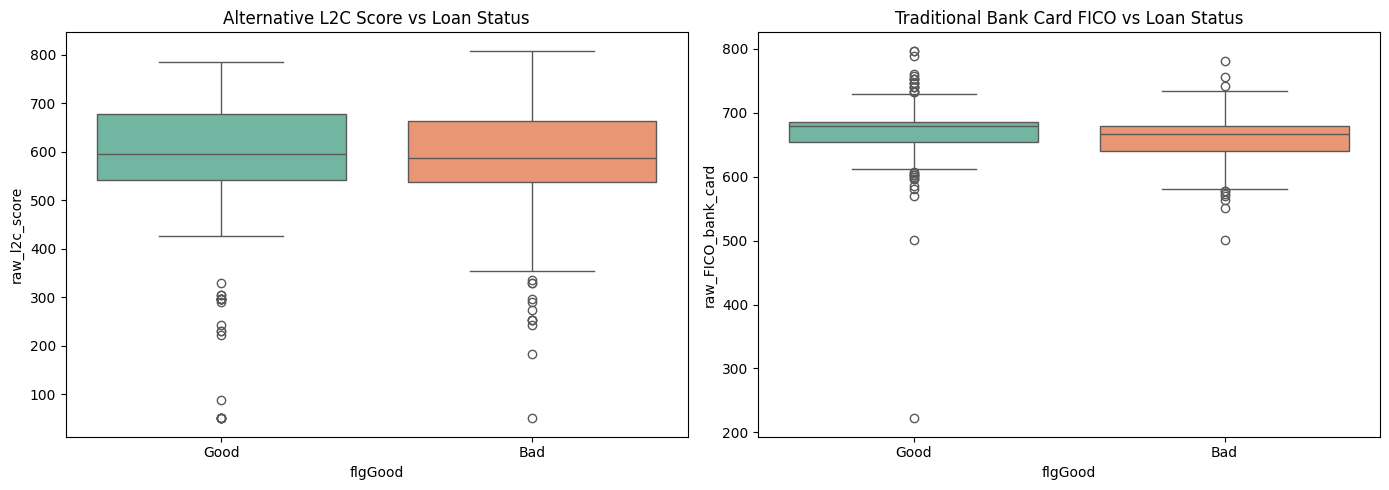

In [30]:
# Visualize distributions of raw credit scores against loan status

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=merged_df, x='flgGood', y='raw_l2c_score', ax=axes[0], palette='Set2')
axes[0].set_title('Alternative L2C Score vs Loan Status')

sns.boxplot(data=merged_df, x='flgGood', y='raw_FICO_bank_card', ax=axes[1], palette='Set2')
axes[1].set_title('Traditional Bank Card FICO vs Loan Status')

plt.tight_layout()
plt.show()

In [30]:
# Univariate Analysis

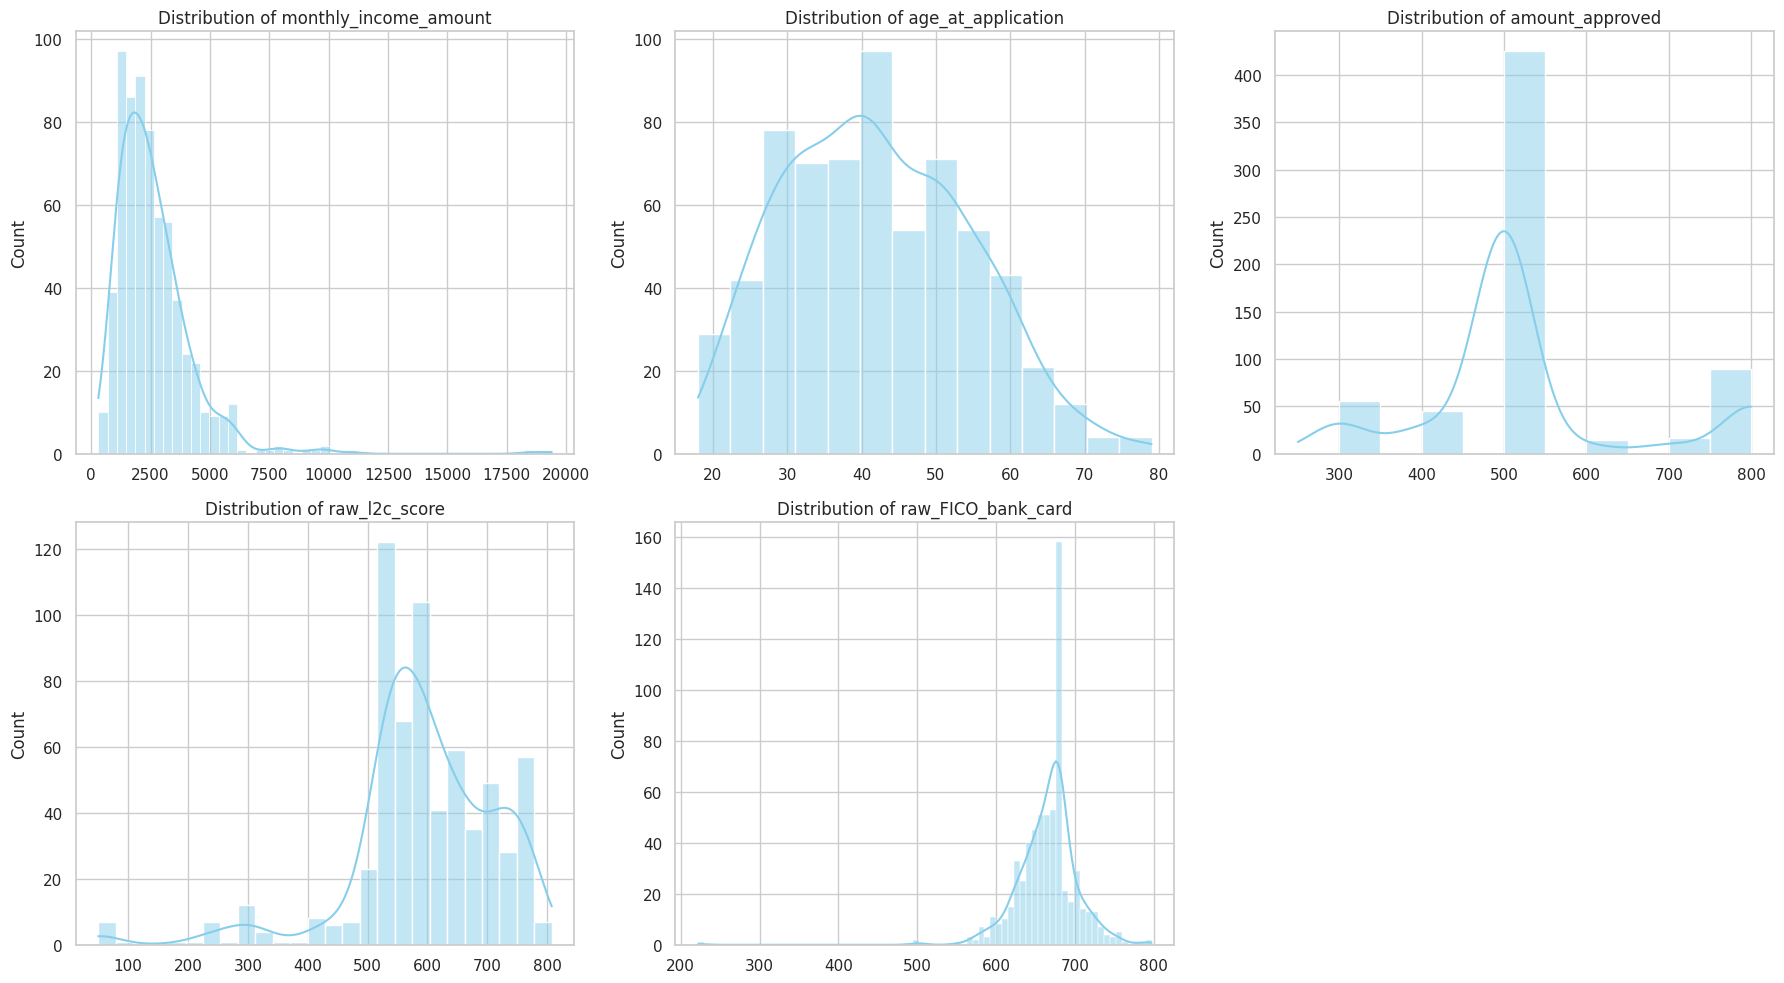

In [32]:

# Set plotting style
sns.set_theme(style="whitegrid")

# Define numerical variables of interest
num_cols = ['monthly_income_amount', 'age_at_application', 'amount_approved', 'raw_l2c_score', 'raw_FICO_bank_card']

# 1. Univariate Analysis: Distributions of continuous variables
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(merged_df[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('')

# Hide the last empty subplot
axes[-1].axis('off')
plt.tight_layout()
plt.show()

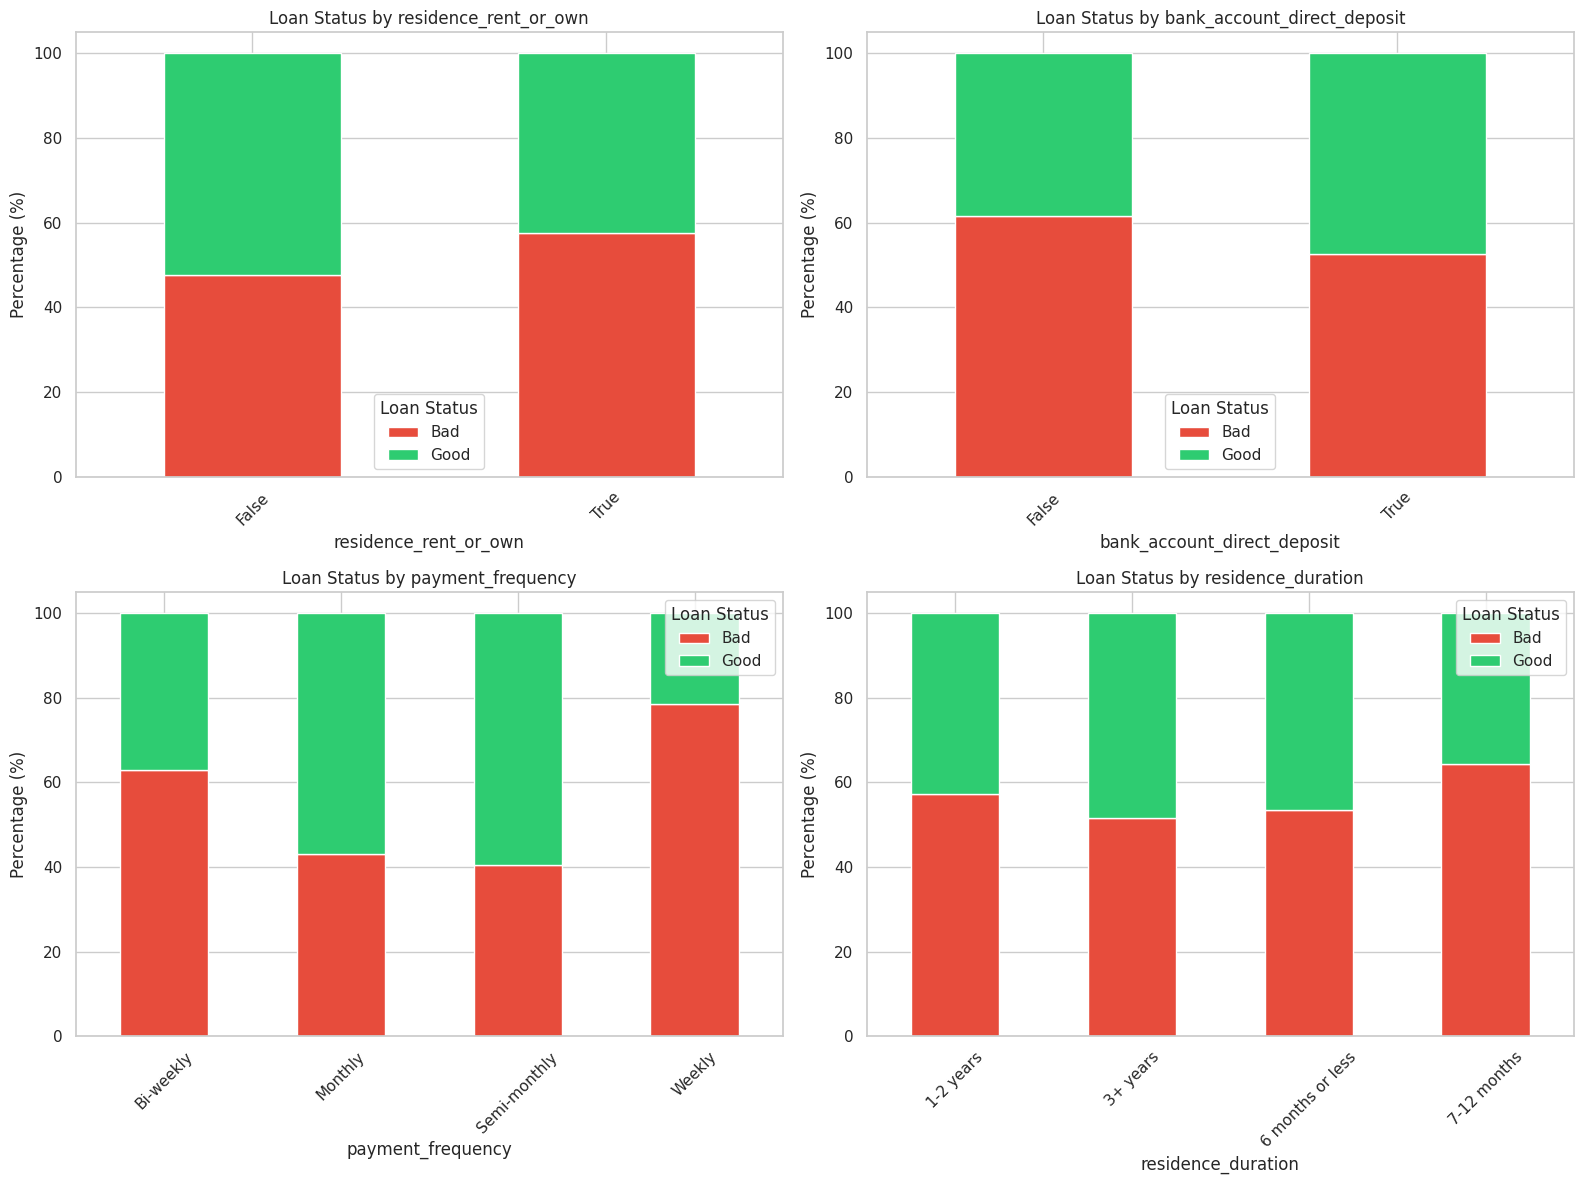

In [33]:
# 2. Bivariate Analysis: Categorical Features vs Target Variable (flgGood)
cat_cols = ['residence_rent_or_own', 'bank_account_direct_deposit', 'payment_frequency', 'residence_duration']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # Calculate percentage within each category
    grouped = merged_df.groupby(col)['flgGood'].value_counts(normalize=True).unstack() * 100

    grouped.plot(kind='bar', stacked=True, ax=axes[i], color=['#e74c3c', '#2ecc71'])
    axes[i].set_title(f'Loan Status by {col}')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(col)
    axes[i].legend(title='Loan Status')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

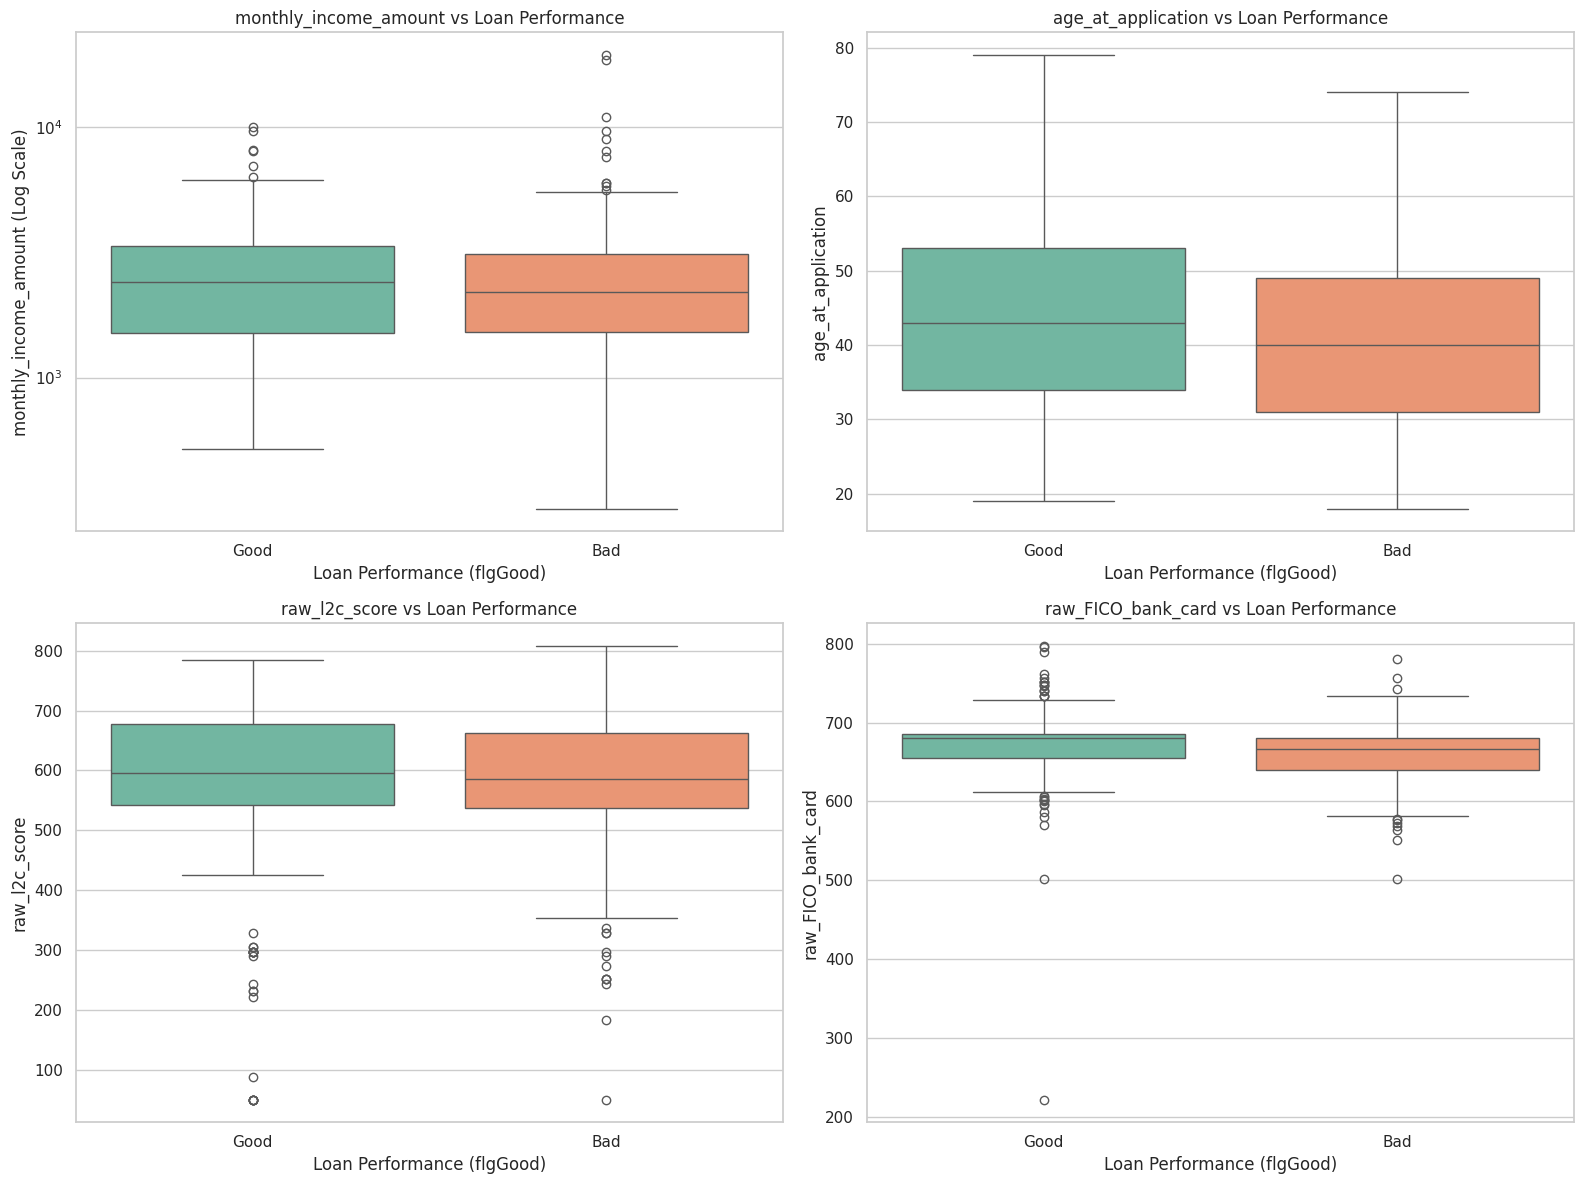

In [34]:
# 3. Bivariate Analysis: Numerical Features vs Target Variable (flgGood)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

biv_num_cols = ['monthly_income_amount', 'age_at_application', 'raw_l2c_score', 'raw_FICO_bank_card']

for i, col in enumerate(biv_num_cols):
    sns.boxplot(data=merged_df, x='flgGood', y=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} vs Loan Performance')
    axes[i].set_xlabel('Loan Performance (flgGood)')

    # Use a log scale for income due to skewness/outliers
    if col == 'monthly_income_amount':
        axes[i].set_yscale('log')
        axes[i].set_ylabel(f'{col} (Log Scale)')

plt.tight_layout()
plt.show()

### **Insights from Univariate & Bivariate Analysis**

* **Income & Credit Scores**: Higher alternative scores (`raw_l2c_score`) and FICO bank card scores correspond to a higher ratio of Good loans. Incomes are heavily right-skewed, warranting logarithmic scaling during modeling.
* **Direct Deposit**: Applicants utilizing direct deposit demonstrate a higher percentage of successfully repaid loans, signaling stable cash flows.
* **Residence Status & Duration**: Longer durations of residence tend to correlate with lower default frequencies, suggesting stronger baseline stability.

### **Data Preparation for Model Training**
In this step, we will prepare the cleaned dataset for machine learning:
1. **Feature Selection**: Select relevant demographic, financial, and credit bureau features.
2. **Categorical Encoding**: Convert categorical variables such as `residence_rent_or_own`, `bank_account_direct_deposit`, `payment_frequency`, and `residence_duration` into machine-readable numeric formats.
3. **Target Variable Encoding**: Map the target `flgGood` variable to binary values (`Good` -> 1, `Bad` -> 0).
4. **Train-Test Split**: Partition the dataset into an 80/20 train-test split for model evaluation.

In [35]:
from sklearn.model_selection import train_test_split

# Create a copy of the merged dataframe for feature engineering
features_df = merged_df.copy()

# Map target variable 'flgGood': 'Good' -> 1, 'Bad' -> 0
features_df['target'] = features_df['flgGood'].map({'Good': 1, 'Bad': 0})

features_df.head()

,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money,customer_id_clean,age_at_application,idLoan,flgGood,target
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,614,574,600,656,561,9ECE67D6C5,19,9ECE67D6C5-01,Good,1
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,708,501,550,651,563,5C2C402094,20,5C2C402094-01,Bad,0
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,687,522,561,661,598,E6254CAD30,30,E6254CAD30-01,Good,1
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,616,560,552,634,591,49FB42F51D,34,49FB42F51D-01,Bad,0
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,681,603,654,659,636,195FBE5739,30,195FBE5739-01,Good,1


In [36]:
# Drop columns that are IDs, timestamps, or directly leak the target

columns_to_drop = [
    'customer_id', 'customer_id_clean', 'idLoan', 'flgGood', 'target',
    'status', 'birth_date', 'application_when', 'email'
]

In [38]:
# Define X (features) and y (target)
y = features_df['target']
X_raw = features_df.drop(columns=columns_to_drop)

X_raw.head()

,amount_requested,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,loan_duration,payment_ach,num_payments,payment_amount,amount_approved,duration_approved,...,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money,age_at_application
0,500,True,0,True,3,True,6,138.48,500,3,...,Mobile,None,Other,1560,614,574,600,656,561,19
1,500,True,0,False,6,True,13,77.39,500,6,...,Mobile,None,Other,900,708,501,550,651,563,20
2,400,True,620,True,6,True,13,61.91,400,6,...,Mobile,None,Other,1434,687,522,561,661,598,30
3,500,False,785,False,4,True,8,108.48,500,4,...,Mobile,None,Other,1600,616,560,552,634,591,34
4,300,True,700,True,4,True,8,65.09,300,4,...,Mobile,Home,Other,1360,681,603,654,659,636,30


In [39]:
y.head()

,target
0,1
1,0
2,1
3,0
4,1


In [40]:
# Select categorical and numerical columns dynamically

categorical_cols = X_raw.select_dtypes(include=['object', 'bool', 'category']).columns.tolist()
numerical_cols = X_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [41]:
# Apply One-Hot Encoding to categorical variables

X_encoded = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True)

In [42]:

# Split the dataset into train and test sets (80% train, 20% test) with stratify to maintain class balance

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Class distribution in Training set:\n{y_train.value_counts(normalize=True)}")

Training set shape: (520, 51)
Test set shape: (130, 51)
Class distribution in Training set:
target
0    0.542308
1    0.457692
Name: proportion, dtype: float64


### **Baseline Model Training & Evaluation**
We will train a baseline **Random Forest Classifier** on the prepared training dataset and evaluate its performance on the test set using standard classification metrics (Accuracy, Precision, Recall, and F1-Score).

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Initialize the baseline Random Forest model with balanced class weight and a fixed random state
baseline_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

# Train the baseline model
baseline_rf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = baseline_rf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Baseline Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Bad (0)', 'Good (1)']))

Baseline Model Accuracy: 0.5462

Classification Report:
              precision    recall  f1-score   support

     Bad (0)       0.58      0.62      0.60        71
    Good (1)       0.50      0.46      0.48        59

    accuracy                           0.55       130
   macro avg       0.54      0.54      0.54       130
weighted avg       0.54      0.55      0.54       130



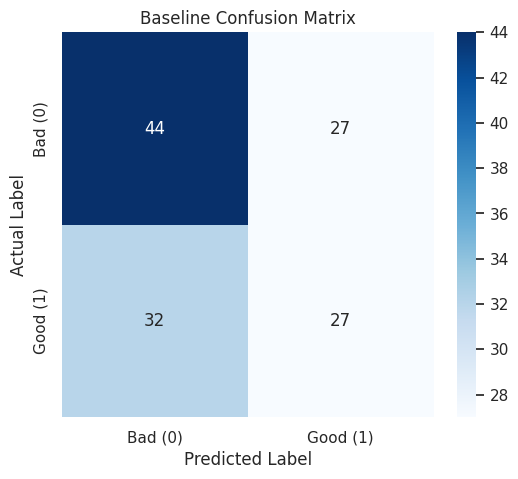

In [44]:
# Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Bad (0)', 'Good (1)'], yticklabels=['Bad (0)', 'Good (1)'])
plt.title('Baseline Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

### **Advanced Model Training & Selection**
We will compare three advanced gradient boosting frameworks:
1. **XGBoost Classifier**
2. **LightGBM Classifier**
3. **CatBoost Classifier**

These algorithms are state-of-the-art for tabular tabular data and usually offer superior generalization compared to baseline Random Forests.

In [45]:
# Install necessary libraries if not present
!pip install -q xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.1 MB/s eta 0:00:00


In [46]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score
import pandas as pd


In [48]:

# Standardize column names for XGBoost/LightGBM (removing special characters/spaces that can cause issues)

X_train_clean = X_train.rename(columns = lambda x: x.replace('[', '').replace(']', '').replace('<', '').replace(' ', '_'))
X_test_clean = X_test.rename(columns = lambda x: x.replace('[', '').replace(']', '').replace('<', '').replace(' ', '_'))

X_train_clean.head()

,amount_requested,monthly_rent_amount,loan_duration,num_payments,payment_amount,amount_approved,duration_approved,payment_amount_approved,address_zip,bank_routing_number,...,how_use_money_Car,how_use_money_Gifts_/_Leisure,how_use_money_Medical,how_use_money_Other,how_use_money_Pay_off_loans_/_overdrawn_acct,how_use_money_Rent,how_use_money_Rent_/_Mortgage,how_use_money_School,how_use_money_Unknown,how_use_money_Won't_say
124,800,1075,8,13,77.39,500,6,67.57,84043,325070760,...,False,False,False,True,False,False,False,False,False,False
102,600,500,8,13,77.39,500,6,67.57,84043,124302150,...,False,False,False,True,False,False,False,False,False,False
445,500,400,5,10,92.17,500,5,92.17,84111,124001545,...,False,False,False,False,False,False,False,False,False,False
394,800,650,8,13,77.39,500,6,77.39,84106,124002971,...,False,False,False,False,False,False,False,False,False,False
384,500,620,8,8,144.85,500,8,144.85,84070,124001545,...,False,False,False,True,False,False,False,False,False,False


In [49]:

# Initialize models

models = {
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, use_label_encoder=False, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(iterations=150, depth=5, learning_rate=0.05, random_state=42, verbose=0)
}

results = []

# Train and evaluate each model

for name, model in models.items():
    model.fit(X_train_clean, y_train)
    preds = model.predict(X_test_clean)
    probs = model.predict_proba(X_test_clean)[:, 1]

    acc = accuracy_score(y_test, preds)
    auc = roc_auc_score(y_test, probs)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'ROC-AUC': auc
    })

    print(f"=== {name} ===")
    print(classification_report(y_test, preds, target_names=['Bad (0)', 'Good (1)']))
    print(f"ROC-AUC Score: {auc:.4f}\n")



=== XGBoost ===
              precision    recall  f1-score   support

     Bad (0)       0.65      0.68      0.66        71
    Good (1)       0.59      0.56      0.57        59

    accuracy                           0.62       130
   macro avg       0.62      0.62      0.62       130
weighted avg       0.62      0.62      0.62       130

ROC-AUC Score: 0.6180

=== LightGBM ===
              precision    recall  f1-score   support

     Bad (0)       0.64      0.55      0.59        71
    Good (1)       0.54      0.63      0.58        59

    accuracy                           0.58       130
   macro avg       0.59      0.59      0.58       130
weighted avg       0.59      0.58      0.59       130

ROC-AUC Score: 0.5949

=== CatBoost ===
              precision    recall  f1-score   support

     Bad (0)       0.61      0.61      0.61        71
    Good (1)       0.53      0.53      0.53        59

    accuracy                           0.57       130
   macro avg       0.57      0.5

In [50]:
# Compare results in a DataFrame

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,ROC-AUC
0,XGBoost,0.623077,0.618047
1,LightGBM,0.584615,0.594891
2,CatBoost,0.569231,0.611124


### **Exporting Model & Metadata for Deployment**
We will save the best model (`XGBoost`) and the list of columns to disk using `joblib` so they can be easily loaded in the Streamlit app.

In [52]:
import joblib

# Retrieve the best-performing XGBoost model
best_model = models['XGBoost']


In [53]:
# Save the model and feature columns list

joblib.dump(best_model, 'best_loan_model.joblib')
joblib.dump(X_train_clean.columns.tolist(), 'model_features.joblib')

print("Model and features successfully saved to disk!")

Model and features successfully saved to disk!


### **Streamlit Application Structure (`app.py`)**
Below is the complete structure for your Streamlit application. This code loads the saved model, displays form inputs for the loan applicant, reconstructs the necessary dummy/One-Hot Encoded features matching the exact training signature, and makes a predictive risk decision.

In [54]:
streamlit_app_code = """
import streamlit as st
import pandas as pd
import joblib
import numpy as np

# Set page title and layout
st.set_page_config(page_title="Loan Credit Risk Underwriting App", layout="wide")
st.title("🏦 Credit Risk Assessment & Underwriting Dashboard")

# Load pre-trained model and feature template list
@st.cache_resource
def load_assets():
    model = joblib.load('best_loan_model.joblib')
    features = joblib.load('model_features.joblib')
    return model, features

try:
    model, expected_features = load_assets()
    st.sidebar.success("✅ Underwriting model loaded successfully!")
except Exception as e:
    st.sidebar.error(f"❌ Failed to load model files: {e}")

# Input Forms
st.subheader("📋 Enter Applicant Information")
col1, col2, col3 = st.columns(3)

with col1:
    amount_requested = st.number_input("Amount Requested ($)", min_value=100, max_value=5000, value=500, step=50)
    monthly_income = st.number_input("Monthly Income ($)", min_value=0, max_value=50000, value=2500, step=100)
    monthly_rent = st.number_input("Monthly Rent ($)", min_value=0, max_value=10000, value=500, step=50)
    age = st.number_input("Age at Application", min_value=18, max_value=100, value=30, step=1)

with col2:
    residence_rent_or_own = st.selectbox("Do they Rent or Own?", ["Rent", "Own"])
    direct_deposit = st.checkbox("Has Direct Deposit", value=True)
    payment_ach = st.checkbox("Payment via ACH", value=True)
    loan_duration = st.slider("Loan Duration (Months)", min_value=1, max_value=12, value=6)
    num_payments = st.number_input("Number of Scheduled Payments", min_value=1, max_value=36, value=12)

with col3:
    payment_frequency = st.selectbox("Payment Repayment Frequency", ["Bi-weekly", "Monthly", "Semi-monthly", "Weekly"])
    raw_l2c_score = st.slider("Alternative Credit (L2C) Score", min_value=50, max_value=850, value=600)
    raw_FICO_bank_card = st.slider("FICO Bank Card Score", min_value=222, max_value=850, value=650)
    how_use_money = st.selectbox("How is the Loan being Used?", ["Other", "Car", "Rent", "Medical", "School", "Gifts_/_Leisure"])

# Predict trigger
if st.button("🔍 Assess Credit Risk Outcome", type="primary"):
    # Initialize DataFrame with identical structure as expected_features
    input_row = pd.DataFrame(0, index=[0], columns=expected_features)

    # Map Numerical inputs
    input_row['amount_requested'] = amount_requested
    input_row['monthly_rent_amount'] = monthly_rent
    input_row['loan_duration'] = loan_duration
    input_row['num_payments'] = num_payments
    input_row['monthly_income_amount'] = monthly_income
    input_row['raw_l2c_score'] = raw_l2c_score
    input_row['raw_FICO_bank_card'] = raw_FICO_bank_card
    input_row['age_at_application'] = age

    # Map Boolean categories
    if residence_rent_or_own == "Rent":
        input_row['residence_rent_or_own_True'] = 1
    if direct_deposit:
        input_row['bank_account_direct_deposit_True'] = 1
    if payment_ach:
        input_row['payment_ach_True'] = 1

    # Map Categorical selections
    freq_col = f"payment_frequency_{payment_frequency}"
    if freq_col in input_row.columns:
        input_row[freq_col] = 1

    use_col = f"how_use_money_{how_use_money}"
    if use_col in input_row.columns:
        input_row[use_col] = 1

    # Predict Probability and Class
    probability_good = model.predict_proba(input_row)[0][1] * 100
    prediction = model.predict(input_row)[0]

    # Output Results
    st.markdown("--- ")
    if prediction == 1:
        st.balloons()
        st.success(f"🟢 **APPROVED**: The applicant is evaluated as a **Low-Risk (GOOD)** client. Probability of default-free completion: **{probability_good:.1f}%**")
    else:
        st.error(f"🔴 **DECLINED**: The applicant is evaluated as a **High-Risk (BAD)** client. Probability of default-free completion: **{probability_good:.1f}%**")
"""

# Write this script definition to disk
with open('app.py', 'w') as f:
    f.write(streamlit_app_code)

print("Streamlit app script 'app.py' successfully generated and saved!")

Streamlit app script 'app.py' successfully generated and saved!
